# Pruebas estadísticas — DeLong, Diebold–Mariano, MCS y tamaños de efecto

El test de Friedman con el post-hoc de Nemenyi compara **rangos entre folds**: dice si un modelo queda sistemáticamente por delante de otro en los bloques fold × balanceo × optimizador. Este notebook agrega pruebas que miran el problema desde otros ángulos:

| Prueba | Pregunta | Unidad de análisis |
|---|---|---|
| W de Kendall | ¿Qué tan fuerte es el efecto que detecta Friedman? | bloques (folds) |
| Nemenyi por pares (`scikit-posthocs`) | ¿Qué pares de modelos difieren? | bloques (folds) |
| DeLong | ¿La diferencia de AUC entre dos clasificadores es significativa? | los 5,320 vinos (predicciones OOF) |
| Diebold–Mariano | ¿La diferencia de error entre dos modelos de regresión es significativa? | los 5,320 vinos |
| MCS (*Model Confidence Set*) | ¿Qué configuraciones no se pueden distinguir de la mejor? | los 5,320 vinos |
| Tamaños de efecto pareados | ¿La diferencia es grande o solo consistente? | bloques (folds) |
| Bootstrap | ¿Cuánta incertidumbre tienen las métricas finales? | los 5,320 vinos |

Las pruebas por vino (DeLong, Diebold–Mariano, MCS) **condicionan en los modelos entrenados**: miden la incertidumbre por la muestra de prueba, no la variabilidad de reentrenar. Por eso tienen más potencia que Nemenyi y conviene leerlas juntas. Cuando hay varias comparaciones se ajustan los p-valores con Holm.

Figuras `fig18`–`fig22` y tablas `tabla14`–`tabla20`.

In [1]:
import itertools
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import scikit_posthocs as sp
from scipy import stats
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, f1_score, mean_absolute_error,
                             precision_score, r2_score, recall_score, roc_auc_score)
from IPython.display import display

warnings.filterwarnings("ignore")
%matplotlib inline

RUTA_MODELADO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RUTA_MODELADO) not in sys.path:
    sys.path.insert(0, str(RUTA_MODELADO))

from src import config
from src.entorno import versiones
from src.estadistica import (conjunto_confianza_modelos, delong, diebold_mariano, efecto_pareado,
                             friedman_nemenyi, holm, ic_bootstrap)
from src.graficos import (AQUA, AZUL, AZULES, EJE, ETIQUETA_BALANCEO, FONDO, GRIS_NEUTRO, NARANJA, TINTA, TINTA_2,
                          TINTA_3, aplicar_estilo, corto, encabezado, guardar, guardar_tabla, intervalos, luminancia)
from src.predicciones import cargar_oof
from src.seleccion import CLAVES, cargar_log, mejor_por_modelo, recomendada, resumir

aplicar_estilo()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
display(versiones().set_index("paquete").T)

paquete,python,numpy,pandas,scipy,scikit-learn,imbalanced-learn,xgboost,optuna,deap,joblib,statsmodels,scikit-posthocs,shap,lime,matplotlib,seaborn
versión,3.12.14,2.4.4,3.0.2,1.17.1,1.8.0,0.14.2,3.4.1,5.0.0,1.4.4,1.6.0,0.15.0,0.16.1,0.52.0,0.2.0.1,3.10.8,0.13.2


In [2]:
clf, reg = cargar_log("clasificacion"), cargar_log("regresion")
resumen_clf, resumen_reg = resumir(clf, "clasificacion"), resumir(reg, "regresion")
oof_clf, oof_reg = cargar_oof("clasificacion"), cargar_oof("regresion")
mejores_clf = mejor_por_modelo(resumen_clf).sort_values("auc", ascending=False).reset_index(drop=True)
mejores_reg = mejor_por_modelo(resumen_reg).sort_values("rmse").reset_index(drop=True)
sin_knn = clf[clf["modelo"] != "KNN"]


def serie(oof, fila, columna):
    g = oof[(oof["modelo"] == fila["modelo"]) & (oof["balanceo"] == fila["balanceo"])
            & (oof["optimizador"] == fila["optimizador"])].sort_values("idx")
    return g[columna].to_numpy()


y_clf = serie(oof_clf, mejores_clf.iloc[0], "y_true")
y_reg = serie(oof_reg, mejores_reg.iloc[0], "y_true")
puntajes = {f["modelo"]: serie(oof_clf, f, "score") for f in mejores_clf.to_dict("records")}
errores = {f["modelo"]: y_reg - serie(oof_reg, f, "pred") for f in mejores_reg.to_dict("records")}
print("Clasificación (mejor score interno de cada modelo):", ", ".join(f"{corto(m)}" for m in puntajes))
print("Regresión:", ", ".join(errores))

Clasificación (mejor score interno de cada modelo): Random Forest, XGBoost, SVM, KNN, Reg. logística, Decision Tree, Naive Bayes
Regresión: Random Forest, XGBoost, SVR, KNN, Ridge, Lasso, Decision Tree


## 1. Tamaño del efecto de Friedman: W de Kendall

Friedman responde *si* hay diferencias; con muchos bloques puede rechazar aunque el efecto sea mínimo. La **W de Kendall**, W = χ²_F / (N (k − 1)), mide cuánto coinciden los bloques al ordenar los tratamientos: 0 = cada bloque ordena distinto, 1 = todos ordenan igual. Umbrales usuales: 0.1 pequeño, 0.3 mediano, 0.5 grande. Se recalculan las siete pruebas del notebook de resultados con los mismos bloques.

In [3]:
def magnitud_w(w):
    return "muy pequeño" if w < 0.1 else "pequeño" if w < 0.3 else "mediano" if w < 0.5 else "grande"


pruebas = [
    ("Clasificación", "Modelos", "AUC-ROC", friedman_nemenyi(clf[clf["balanceo"] != "class_weight"], "modelo",
                                                             ["balanceo", "optimizador", "fold_externo"], "auc")),
    ("Clasificación", "Modelos", "F1", friedman_nemenyi(clf[clf["balanceo"] != "class_weight"], "modelo",
                                                        ["balanceo", "optimizador", "fold_externo"], "f1")),
    ("Clasificación", "Balanceo", "F1", friedman_nemenyi(sin_knn, "balanceo", ["modelo", "optimizador", "fold_externo"], "f1")),
    ("Clasificación", "Balanceo", "AUC-ROC", friedman_nemenyi(sin_knn, "balanceo", ["modelo", "optimizador", "fold_externo"], "auc")),
    ("Clasificación", "Optimizador", "AUC-ROC", friedman_nemenyi(clf, "optimizador", ["modelo", "balanceo", "fold_externo"], "auc")),
    ("Regresión", "Modelos", "RMSE", friedman_nemenyi(reg, "modelo", ["optimizador", "fold_externo"], "rmse", mayor_es_mejor=False)),
    ("Regresión", "Optimizador", "RMSE", friedman_nemenyi(reg, "optimizador", ["modelo", "fold_externo"], "rmse", mayor_es_mejor=False)),
]
tabla14 = pd.DataFrame([{"tarea": t, "factor": f, "metrica": m, "N_bloques": r["N"], "k": r["k"], "chi2": r["chi2"],
                         "p_friedman": r["p"], "p_iman_davenport": r["p_ID"], "cd_nemenyi": r["cd"], "W_kendall": r["W"],
                         "magnitud": magnitud_w(r["W"])} for t, f, m, r in pruebas])
guardar_tabla(tabla14, "tabla14_friedman_w_kendall")
display(tabla14.round({"chi2": 2, "cd_nemenyi": 3, "W_kendall": 3}))

,tarea,factor,metrica,N_bloques,k,chi2,p_friedman,p_iman_davenport,cd_nemenyi,W_kendall,magnitud
0,Clasificación,Modelos,AUC-ROC,60,7,336.85,1.025397e-69,1.602618e-207,1.163,0.936,grande
1,Clasificación,Modelos,F1,60,7,157.69,1.823813e-31,1.548690e-41,1.163,0.438,mediano
2,Clasificación,Balanceo,F1,120,4,97.03,6.766407e-21,3.560174e-24,0.428,0.270,pequeño
3,Clasificación,Balanceo,AUC-ROC,120,4,67.01,1.866398e-14,7.134600e-16,0.428,0.186,pequeño
4,Clasificación,Optimizador,AUC-ROC,135,4,8.48,3.712304e-02,3.650694e-02,0.404,0.021,muy pequeño
5,Regresión,Modelos,RMSE,20,7,110.91,1.311635e-21,1.902066e-61,2.014,0.924,grande
6,Regresión,Optimizador,RMSE,35,4,0.74,8.639939e-01,8.675587e-01,0.793,0.007,muy pequeño


> **Resultado:** la elección del modelo tiene un efecto **grande** y muy consistente: W = 0.94 en clasificación (AUC) y 0.92 en regresión, o sea que casi todos los bloques ordenan los modelos de la misma manera. En F1 el efecto del modelo baja a mediano (0.44), porque el F1 depende también del balanceo. El balanceo tiene un efecto pequeño sobre el F1 (0.27) y sobre el AUC (0.19). El optimizador es el caso más ilustrativo: en clasificación Friedman rechaza la igualdad (p = 0.037), pero W = 0.02, un efecto despreciable; con 135 bloques, una diferencia mínima ya alcanza a ser "significativa". En regresión ni siquiera es significativo (p = 0.86, W = 0.007).

## 2. Comparaciones por pares: Nemenyi frente a DeLong y Diebold–Mariano

A la izquierda, los p-valores de Nemenyi para cada par de modelos (`scikit-posthocs`, mismos bloques que el diagrama de diferencia crítica). A la derecha, la prueba equivalente sobre las predicciones de cada vino: **DeLong** compara el AUC de dos clasificadores evaluados sobre los mismos casos (tiene en cuenta que sus puntajes están correlacionados) y **Diebold–Mariano** compara el error cuadrático medio de dos modelos de regresión con una prueba t sobre la diferencia de pérdidas (con la corrección de Harvey, Leybourne y Newbold). Ambas usan la combinación con mejor score interno de cada modelo y p-valores ajustados por Holm (21 pares).

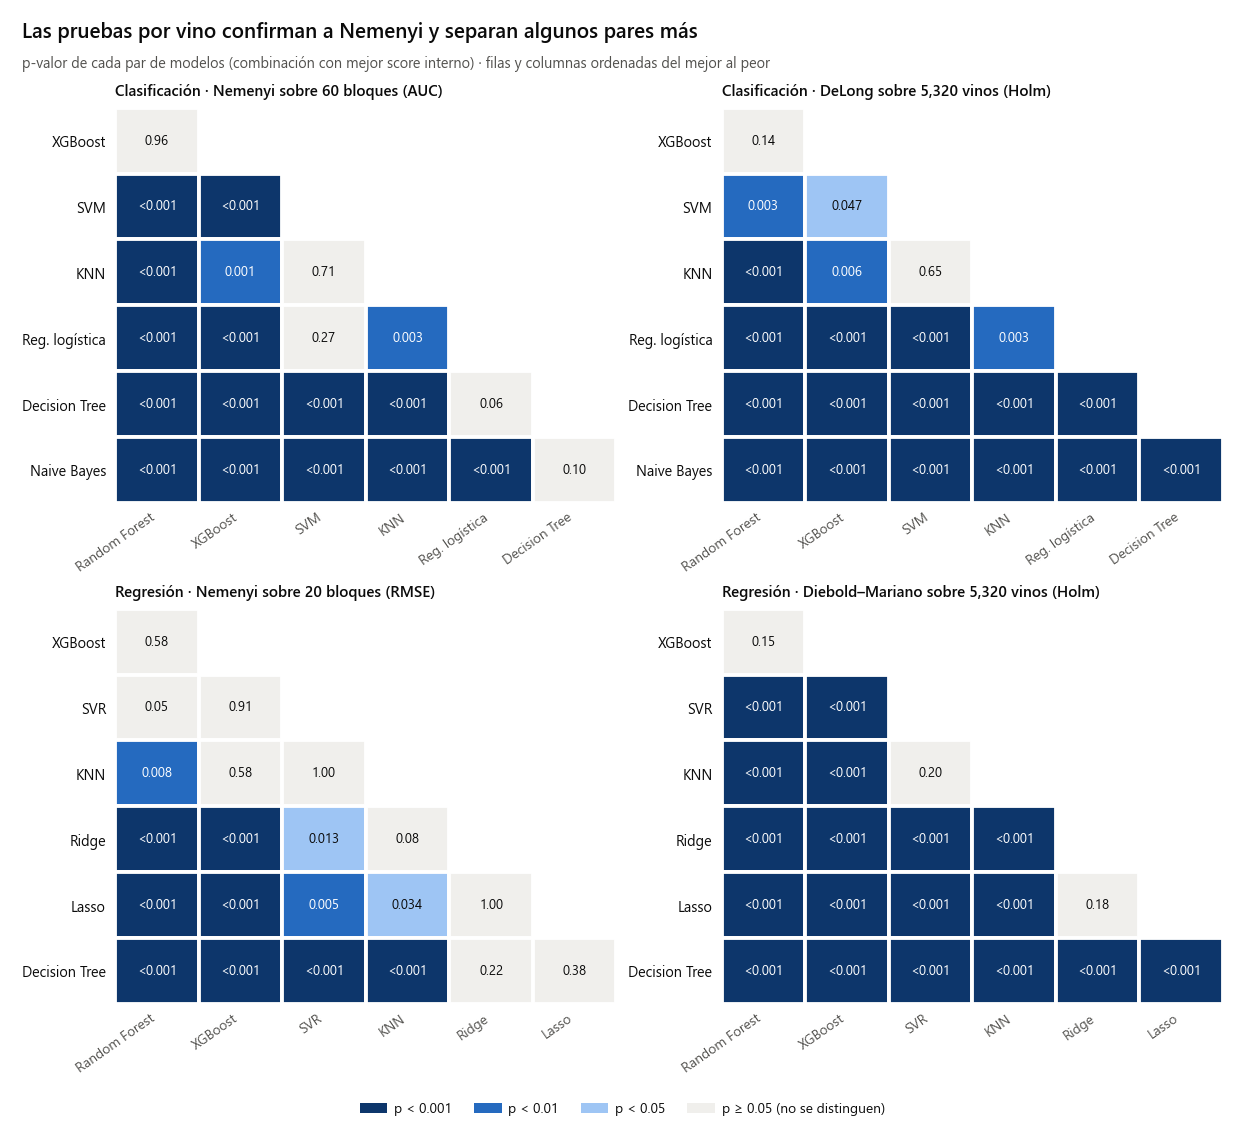

In [4]:
def p_nemenyi(resultado, mayor_es_mejor=True):
    tabla = resultado["tabla"]
    p = sp.posthoc_nemenyi_friedman((tabla if mayor_es_mejor else -tabla).to_numpy())
    p.index = p.columns = tabla.columns
    return p


filas = []
for a, b in itertools.combinations(puntajes, 2):
    filas.append({"modelo_a": a, "modelo_b": b, **delong(y_clf, puntajes[a], puntajes[b])})
tabla15 = pd.DataFrame(filas)
tabla15["p_holm"] = holm(tabla15["p"])

filas = []
for a, b in itertools.combinations(errores, 2):
    d = errores[a] ** 2 - errores[b] ** 2
    ee = d.std(ddof=1) / np.sqrt(len(d))
    t_crit = stats.t.ppf(0.975, len(d) - 1)
    filas.append({"modelo_a": a, "modelo_b": b, **diebold_mariano(errores[a], errores[b]),
                  "ic_inf": d.mean() - t_crit * ee, "ic_sup": d.mean() + t_crit * ee})
tabla17 = pd.DataFrame(filas)
tabla17["p_holm"] = holm(tabla17["p"])
guardar_tabla(tabla15.round(6), "tabla15_delong_pares_de_modelos")
guardar_tabla(tabla17.round(6), "tabla17_diebold_mariano_pares_de_modelos")


def matriz_pares(tabla, orden, columna="p_holm"):
    m = pd.DataFrame(np.nan, index=orden, columns=orden)
    for fila in tabla.itertuples():
        m.loc[fila.modelo_a, fila.modelo_b] = m.loc[fila.modelo_b, fila.modelo_a] = getattr(fila, columna)
    return m


NIVELES = [0, 0.001, 0.01, 0.05, 1.0001]
COLORES_P = [AZULES[6], AZULES[4], AZULES[1], GRIS_NEUTRO]
cmap_p = mcolors.ListedColormap(COLORES_P)
norm_p = mcolors.BoundaryNorm(NIVELES, cmap_p.N)


def texto_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}" if p < 0.05 else f"{p:.2f}"


def p_igual(p):
    return "p < 0.001" if p < 0.001 else f"p = {texto_p(p)}"


def triangulo_p(ax, matriz, titulo):
    n = len(matriz)
    nombres = [corto(m) for m in matriz.index]
    for i in range(n):
        for j in range(i):
            p = matriz.iloc[i, j]
            color = cmap_p(norm_p(p))
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor=FONDO, lw=2.5))
            ax.text(j, i, texto_p(p), ha="center", va="center", fontsize=8.6,
                    color=FONDO if luminancia(color) < 0.18 else TINTA)
    ax.set_xlim(-0.5, n - 1.5)
    ax.set_ylim(n - 0.5, 0.5)
    ax.set_xticks(range(n - 1), labels=nombres[:-1], rotation=35, ha="right")
    ax.set_yticks(range(1, n), labels=nombres[1:])
    ax.tick_params(axis="y", labelcolor=TINTA)
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_title(titulo, fontsize=10)


leyenda_p = [Patch(facecolor=c, label=t) for c, t in zip(COLORES_P, ["p < 0.001", "p < 0.01", "p < 0.05", "p ≥ 0.05 (no se distinguen)"])]
orden_clf = list(puntajes)
orden_reg = list(errores)
fr_clf, fr_reg = pruebas[0][3], pruebas[5][3]

fig, axes = plt.subplots(2, 2, figsize=(11, 9.4), layout="constrained")
triangulo_p(axes[0, 0], p_nemenyi(fr_clf).loc[orden_clf, orden_clf], f"Clasificación · Nemenyi sobre {fr_clf['N']} bloques (AUC)")
triangulo_p(axes[0, 1], matriz_pares(tabla15, orden_clf), "Clasificación · DeLong sobre 5,320 vinos (Holm)")
triangulo_p(axes[1, 0], p_nemenyi(fr_reg, False).loc[orden_reg, orden_reg], f"Regresión · Nemenyi sobre {fr_reg['N']} bloques (RMSE)")
triangulo_p(axes[1, 1], matriz_pares(tabla17, orden_reg), "Regresión · Diebold–Mariano sobre 5,320 vinos (Holm)")
fig.legend(handles=leyenda_p, loc="outside lower center", ncols=4)
encabezado(fig, "Las pruebas por vino confirman a Nemenyi y separan algunos pares más",
           "p-valor de cada par de modelos (combinación con mejor score interno) · filas y columnas ordenadas del mejor al peor")
guardar(fig, "fig18_p_valores_por_pares")
plt.show()

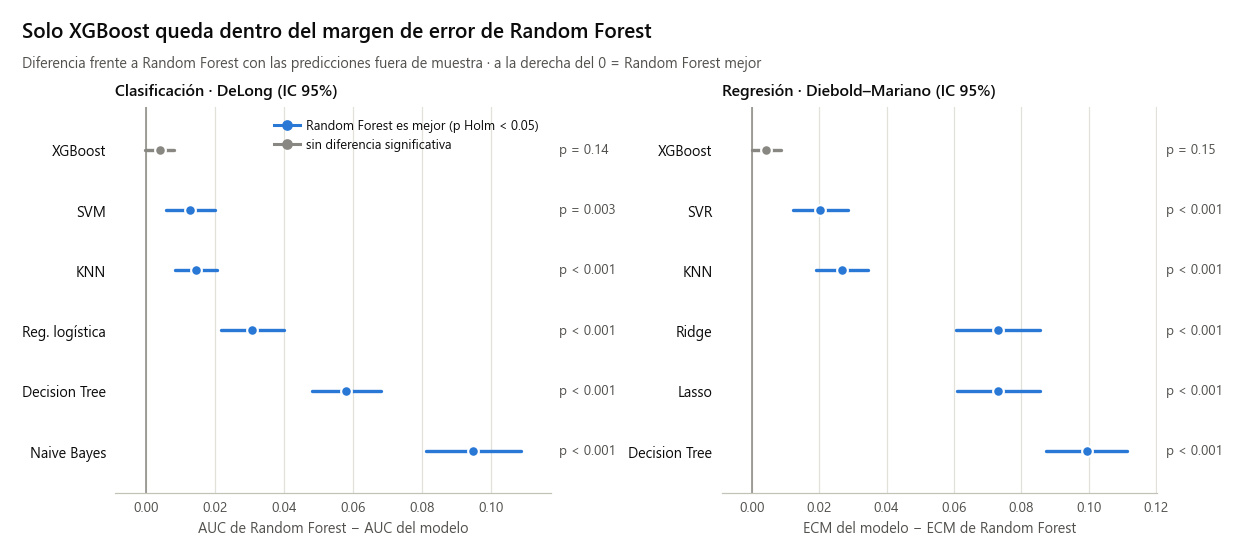

,modelo_b,auc_a,auc_b,diferencia,ic_inf,ic_sup,z,p,p_holm
0,XGBoost,0.8591,0.8552,0.0039,-0.0003,0.0081,1.8059,0.0709,0.1419
1,SVM,0.8591,0.8464,0.0127,0.0056,0.0198,3.5069,0.0005,0.0026
2,KNN,0.8591,0.8446,0.0144,0.0084,0.0204,4.7089,0.0000,0.0000
3,Regresión Logística (L1/L2),0.8591,0.8283,0.0308,0.0217,0.0399,6.6237,0.0000,0.0000
4,Decision Tree,0.8591,0.8011,0.0580,0.0480,0.0680,11.3830,0.0000,0.0000
5,Naive Bayes,0.8591,0.7642,0.0948,0.0810,0.1086,13.4652,0.0000,0.0000


,modelo_b,perdida_a,perdida_b,diferencia,ic_inf,ic_sup,dm,p,p_holm
0,XGBoost,0.4641,0.4685,-0.0043,-0.0087,0.0000,-1.9498,0.0513,0.1538
1,SVR,0.4641,0.4845,-0.0204,-0.0286,-0.0121,-4.8536,0.0000,0.0000
2,KNN,0.4641,0.4909,-0.0267,-0.0345,-0.0190,-6.7864,0.0000,0.0000
3,Ridge,0.4641,0.5372,-0.0731,-0.0854,-0.0607,-11.5833,0.0000,0.0000
4,Lasso,0.4641,0.5374,-0.0732,-0.0856,-0.0609,-11.6252,0.0000,0.0000
5,Decision Tree,0.4641,0.5636,-0.0995,-0.1114,-0.0875,-16.2497,0.0000,0.0000


In [5]:
vs_rf_clf = tabla15[tabla15["modelo_a"] == "Random Forest"].copy()
vs_rf_reg = tabla17[tabla17["modelo_a"] == "Random Forest"].copy()

fig, (ax_c, ax_r) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, tabla, factor, etiqueta in [
    (ax_c, vs_rf_clf, 1, "AUC de Random Forest − AUC del modelo"),
    (ax_r, vs_rf_reg, -1, "ECM del modelo − ECM de Random Forest"),
]:
    est, inf, sup = factor * tabla["diferencia"], factor * tabla["ic_inf"], factor * tabla["ic_sup"]
    if factor < 0:
        inf, sup = sup, inf
    colores = [AZUL if p < 0.05 else TINTA_3 for p in tabla["p_holm"]]
    intervalos(ax, [corto(m) for m in tabla["modelo_b"]], est.to_numpy(), inf.to_numpy(), sup.to_numpy(), colores=colores,
               texto=[p_igual(p) for p in tabla["p_holm"]])
    ax.set_xlabel(etiqueta)
    ax.margins(x=0.08)
ax_c.set_title("Clasificación · DeLong (IC 95%)")
ax_r.set_title("Regresión · Diebold–Mariano (IC 95%)")
ax_c.legend(handles=[Line2D([], [], color=AZUL, marker="o", lw=2, label="Random Forest es mejor (p Holm < 0.05)"),
                     Line2D([], [], color=TINTA_3, marker="o", lw=2, label="sin diferencia significativa")],
            loc="upper right", fontsize=8.5)
encabezado(fig, "Solo XGBoost queda dentro del margen de error de Random Forest",
           "Diferencia frente a Random Forest con las predicciones fuera de muestra · a la derecha del 0 = Random Forest mejor")
guardar(fig, "fig19_diferencias_frente_a_random_forest")
plt.show()
display(vs_rf_clf[["modelo_b", "auc_a", "auc_b", "diferencia", "ic_inf", "ic_sup", "z", "p", "p_holm"]].round(4))
display(vs_rf_reg[["modelo_b", "perdida_a", "perdida_b", "diferencia", "ic_inf", "ic_sup", "dm", "p", "p_holm"]].round(4))

> **Resultado:** las dos miradas coinciden en lo principal. Random Forest no se distingue de XGBoost con ninguna de las dos: con DeLong la diferencia de AUC es 0.004 (IC 95%: −0.0003 a 0.008, p Holm = 0.14) y con Diebold–Mariano la diferencia de error cuadrático medio es 0.004 (p = 0.051 sin ajustar, 0.15 con Holm). Contra todos los demás modelos la ventaja de Random Forest es significativa con ambas pruebas. Las pruebas por vino separan varios pares que Nemenyi no alcanza a distinguir, justamente porque usan cada uno de los 5,320 vinos y no solo el orden entre bloques: en clasificación, SVM frente a la regresión logística y el árbol frente a la regresión logística y a Naive Bayes; en regresión, Random Forest y XGBoost frente a SVR (Nemenyi p = 0.05 y 0.91; Diebold–Mariano p < 0.001) y el árbol frente a Ridge y Lasso. Siguen sin distinguirse Random Forest–XGBoost en las dos tareas, SVM–KNN en clasificación, y SVR–KNN y Ridge–Lasso en regresión (estos dos últimos son prácticamente el mismo modelo lineal).

### 2.1 DeLong para las otras dos decisiones: balanceo y optimizador

Dentro de un mismo modelo se comparan las técnicas de balanceo (contra no balancear) y el optimizador bayesiano contra Grid Search, siempre con el AUC de las predicciones fuera de muestra. Cada familia de comparaciones se ajusta por Holm.

In [6]:
def fila_combo(modelo, balanceo, optimizador):
    return {"modelo": modelo, "balanceo": balanceo, "optimizador": optimizador}


filas = []
for modelo in ["Random Forest", "XGBoost"]:
    familia = []
    referencia = serie(oof_clf, fila_combo(modelo, "sin_balanceo", "Bayesiano"), "score")
    for balanceo in ["class_weight", "SMOTE", "ADASYN"]:
        d = delong(y_clf, serie(oof_clf, fila_combo(modelo, balanceo, "Bayesiano"), "score"), referencia)
        familia.append({"comparacion": f"{balanceo} − sin balanceo", "modelo": modelo, "fijo": "optimizador bayesiano", **d})
    for balanceo in ["sin_balanceo", "class_weight", "SMOTE", "ADASYN"]:
        d = delong(y_clf, serie(oof_clf, fila_combo(modelo, balanceo, "Bayesiano"), "score"),
                   serie(oof_clf, fila_combo(modelo, balanceo, "Grid Search"), "score"))
        familia.append({"comparacion": "Bayesiano − Grid Search", "modelo": modelo, "fijo": ETIQUETA_BALANCEO[balanceo], **d})
    familia = pd.DataFrame(familia)
    for tipo in ["sin balanceo", "Grid Search"]:
        m = familia["comparacion"].str.contains(tipo)
        familia.loc[m, "p_holm"] = holm(familia.loc[m, "p"])
    filas.append(familia)
tabla16 = pd.concat(filas, ignore_index=True)
guardar_tabla(tabla16.round(6), "tabla16_delong_balanceo_y_optimizador")
display(tabla16[["modelo", "comparacion", "fijo", "auc_a", "auc_b", "diferencia", "ic_inf", "ic_sup", "p", "p_holm"]].round(4))

,modelo,comparacion,fijo,auc_a,auc_b,diferencia,ic_inf,ic_sup,p,p_holm
0,Random Forest,class_weight − sin balanceo,optimizador bayesiano,0.8591,0.8546,0.0045,0.0010,0.0079,0.0106,0.0319
1,Random Forest,SMOTE − sin balanceo,optimizador bayesiano,0.8575,0.8546,0.0029,-0.0015,0.0074,0.1915,0.3831
2,Random Forest,ADASYN − sin balanceo,optimizador bayesiano,0.8556,0.8546,0.0010,-0.0043,0.0063,0.7146,0.7146
3,Random Forest,Bayesiano − Grid Search,Sin balanceo,0.8546,0.8556,-0.0010,-0.0027,0.0008,0.2776,0.5551
4,Random Forest,Bayesiano − Grid Search,class_weight,0.8591,0.8606,-0.0015,-0.0035,0.0004,0.1246,0.3737
5,Random Forest,Bayesiano − Grid Search,SMOTE,0.8575,0.8580,-0.0005,-0.0019,0.0010,0.5284,0.5551
6,Random Forest,Bayesiano − Grid Search,ADASYN,0.8556,0.8574,-0.0018,-0.0036,-0.0000,0.0453,0.1810
7,XGBoost,class_weight − sin balanceo,optimizador bayesiano,0.8552,0.8547,0.0005,-0.0026,0.0037,0.7403,1.0000
8,XGBoost,SMOTE − sin balanceo,optimizador bayesiano,0.8569,0.8547,0.0023,-0.0017,0.0062,0.2617,0.7852
9,XGBoost,ADASYN − sin balanceo,optimizador bayesiano,0.8535,0.8547,-0.0012,-0.0057,0.0034,0.6140,1.0000


> **Resultado:** el balanceo prácticamente no mueve el AUC. En XGBoost ninguna técnica cambia el AUC de forma significativa (diferencias entre −0.001 y +0.002) y en Random Forest solo `class_weight` lo sube, apenas 0.0045 (p Holm = 0.03); SMOTE y ADASYN no. Con el optimizador pasa lo esperado: en Random Forest Bayesiano y Grid Search empatan con los cuatro balanceos (diferencias de −0.002 a −0.0005, ninguna significativa), mientras que en XGBoost el bayesiano gana en los cuatro casos (+0.003 a +0.0065), aunque después de Holm solo la diferencia con SMOTE es significativa por sí sola (p Holm = 0.004). Visto vino a vino, la ventaja del bayesiano en XGBoost es real pero chica; donde se ve con más claridad es en la consistencia entre folds, que se mide más abajo con los tamaños de efecto.

## 3. Conjunto de confianza de modelos (MCS)

Comparar todos contra todos crece rápido (con 92 configuraciones serían 4,186 pares). El **MCS** de Hansen, Lunde y Nason (2011) responde otra pregunta: *¿qué configuraciones no se pueden descartar como la mejor?* Parte de todas, prueba si sus pérdidas medias son iguales (estadístico T_max con bootstrap de los vinos, B = 2,000) y, si no lo son, elimina la peor; repite hasta que la igualdad no se rechaza. El conjunto que queda contiene a la mejor configuración con 90% de confianza (α = 0.10). La pérdida es el error cuadrático: en clasificación es el puntaje de Brier de cada vino (las 16 configuraciones de SVM quedan fuera porque no dan probabilidades) y en regresión el error cuadrático de la nota.

In [7]:
def etiqueta_combo(modelo, balanceo, optimizador, tarea):
    texto = corto(modelo)
    if tarea == "clasificacion":
        texto += f" · {ETIQUETA_BALANCEO[balanceo]}"
    return f"{texto} · {optimizador}"


perdidas_clf, perdidas_reg = {}, {}
for (modelo, balanceo, optimizador), g in oof_clf.groupby(CLAVES):
    if g["tipo_score"].iloc[0] == "probabilidad":
        g = g.sort_values("idx")
        perdidas_clf[(modelo, balanceo, optimizador)] = ((g["y_true"] - g["score"]) ** 2).to_numpy()
for (modelo, balanceo, optimizador), g in oof_reg.groupby(CLAVES):
    g = g.sort_values("idx")
    perdidas_reg[(modelo, balanceo, optimizador)] = ((g["y_true"] - g["pred"]) ** 2).to_numpy()


def mcs(perdidas, tarea, alfa=0.10):
    tabla = pd.DataFrame({"|".join(k): v for k, v in perdidas.items()})
    resultado = conjunto_confianza_modelos(tabla, alfa=alfa, B=2000, semilla=config.RANDOM_STATE)
    resultado = resultado.rename(columns={"modelo": "clave"})
    resultado[CLAVES] = resultado["clave"].str.split("|", expand=True)
    resultado.insert(0, "tarea", tarea)
    return resultado[["tarea", *CLAVES, "perdida_media", "paso_eliminacion", "p_mcs", "en_mcs"]]


mcs_clf, mcs_reg = mcs(perdidas_clf, "clasificacion"), mcs(perdidas_reg, "regresion")
tabla18 = pd.concat([mcs_clf, mcs_reg], ignore_index=True)
guardar_tabla(tabla18.round(6), "tabla18_conjunto_confianza_modelos")
print(f"Clasificación: {mcs_clf['en_mcs'].sum()} de {len(mcs_clf)} configuraciones en el MCS (α = 0.10, pérdida Brier)")
print(f"Regresión: {mcs_reg['en_mcs'].sum()} de {len(mcs_reg)} configuraciones en el MCS (α = 0.10, error cuadrático)")
display(mcs_clf.head(12).round(4))
display(mcs_reg.head(8).round(4))

Clasificación: 8 de 92 configuraciones en el MCS (α = 0.10, pérdida Brier)
Regresión: 1 de 28 configuraciones en el MCS (α = 0.10, error cuadrático)


,tarea,modelo,balanceo,optimizador,perdida_media,paso_eliminacion,p_mcs,en_mcs
0,clasificacion,Random Forest,class_weight,Grid Search,0.1090,92,1.0000,True
1,clasificacion,Random Forest,class_weight,Bayesiano,0.1093,91,0.3635,True
2,clasificacion,Random Forest,sin_balanceo,Grid Search,0.1099,90,0.2430,True
3,clasificacion,Random Forest,sin_balanceo,Genético,0.1104,89,0.1495,True
4,clasificacion,Random Forest,class_weight,Random Search,0.1107,88,0.1495,True
5,clasificacion,Random Forest,sin_balanceo,Bayesiano,0.1106,87,0.1260,True
6,clasificacion,Random Forest,sin_balanceo,Random Search,0.1108,86,0.1260,True
7,clasificacion,XGBoost,sin_balanceo,Bayesiano,0.1117,85,0.1260,True
8,clasificacion,XGBoost,sin_balanceo,Random Search,0.1123,84,0.0065,False
9,clasificacion,XGBoost,sin_balanceo,Genético,0.1130,83,0.0065,False


,tarea,modelo,balanceo,optimizador,perdida_media,paso_eliminacion,p_mcs,en_mcs
0,regresion,Random Forest,no_aplica,Grid Search,0.4608,28,1.000,True
1,regresion,Random Forest,no_aplica,Genético,0.4632,27,0.043,False
2,regresion,Random Forest,no_aplica,Bayesiano,0.4641,26,0.043,False
3,regresion,Random Forest,no_aplica,Random Search,0.4650,25,0.043,False
4,regresion,XGBoost,no_aplica,Bayesiano,0.4685,24,0.043,False
5,regresion,XGBoost,no_aplica,Random Search,0.4696,23,0.019,False
6,regresion,XGBoost,no_aplica,Genético,0.4720,22,0.015,False
7,regresion,SVR,no_aplica,Bayesiano,0.4845,21,0.000,False


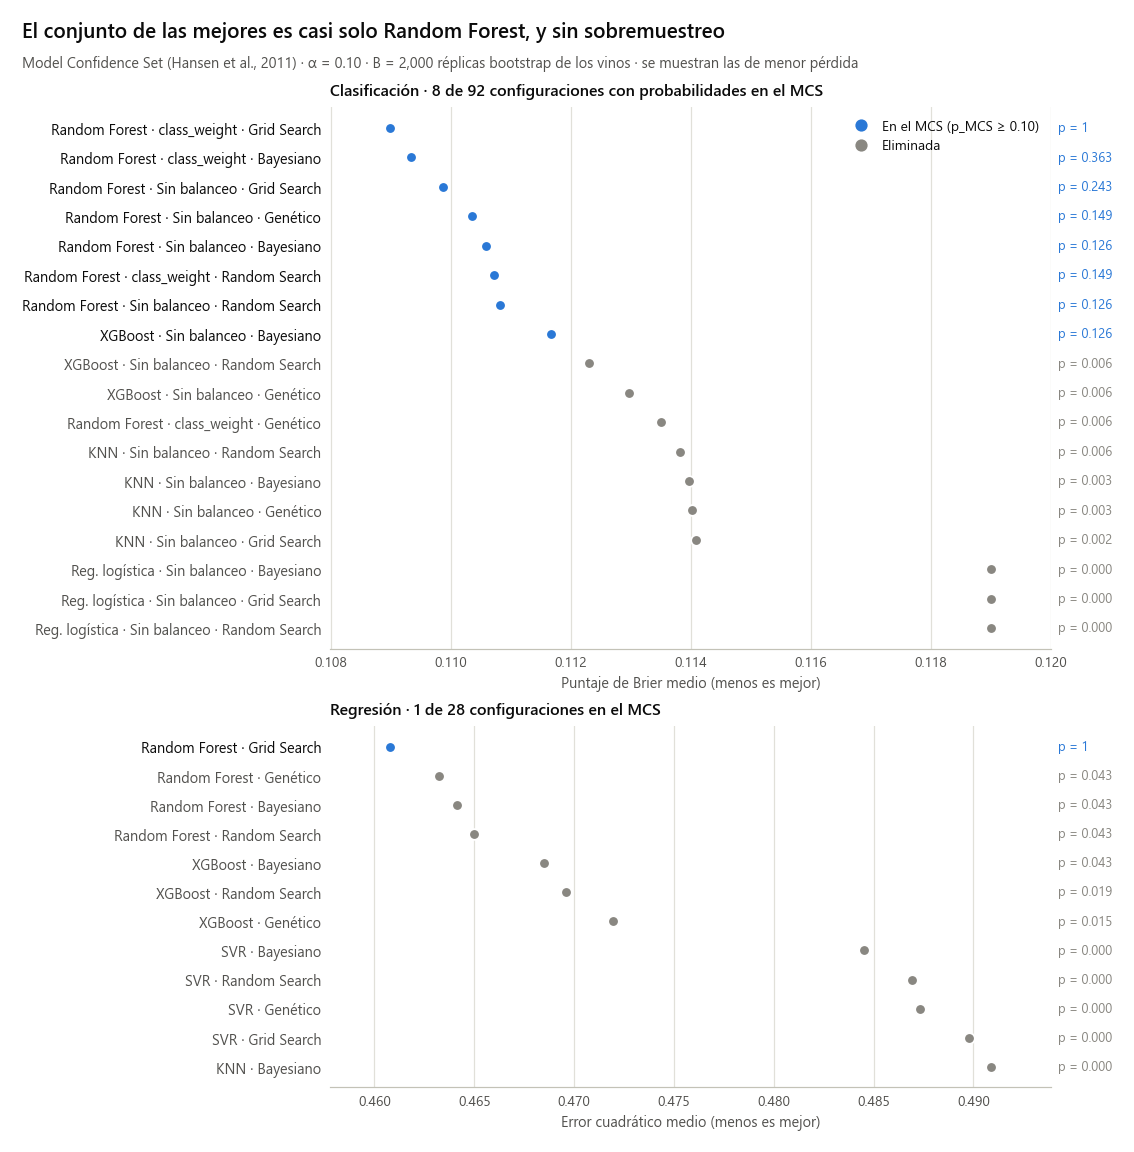

In [8]:
def panel_mcs(ax, tabla, tarea, n, etiqueta_x):
    t = tabla.sort_values("perdida_media").head(n).reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    for yi, fila in zip(y, t.itertuples()):
        color = AZUL if fila.en_mcs else TINTA_3
        ax.plot(fila.perdida_media, yi, "o", ms=7, color=color, mec=FONDO, mew=1.2, zorder=3)
        ax.text(1.01, yi, f"p = {fila.p_mcs:.3f}" if fila.p_mcs < 1 else "p = 1", transform=ax.get_yaxis_transform(),
                va="center", fontsize=8.5, color=AZUL if fila.en_mcs else TINTA_3)
    ax.set_yticks(y, labels=[etiqueta_combo(f.modelo, f.balanceo, f.optimizador, tarea) for f in t.itertuples()])
    for etiqueta, fila in zip(ax.get_yticklabels(), t.itertuples()):
        etiqueta.set_color(TINTA if fila.en_mcs else TINTA_2)
    ax.set_xlabel(etiqueta_x)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.set_ylim(-0.7, len(t) - 0.3)
    ax.margins(x=0.1)


fig, (ax_c, ax_r) = plt.subplots(2, 1, figsize=(10, 9.6), height_ratios=[18, 12], layout="constrained")
panel_mcs(ax_c, mcs_clf, "clasificacion", 18, "Puntaje de Brier medio (menos es mejor)")
panel_mcs(ax_r, mcs_reg, "regresion", 12, "Error cuadrático medio (menos es mejor)")
ax_c.set_title(f"Clasificación · {mcs_clf['en_mcs'].sum()} de {len(mcs_clf)} configuraciones con probabilidades en el MCS")
ax_r.set_title(f"Regresión · {mcs_reg['en_mcs'].sum()} de {len(mcs_reg)} configuraciones en el MCS")
ax_c.legend(handles=[Line2D([], [], ls="", marker="o", ms=7, color=AZUL, label="En el MCS (p_MCS ≥ 0.10)"),
                     Line2D([], [], ls="", marker="o", ms=7, color=TINTA_3, label="Eliminada")], loc="upper right")
encabezado(fig, "El conjunto de las mejores es casi solo Random Forest, y sin sobremuestreo",
           "Model Confidence Set (Hansen et al., 2011) · α = 0.10 · B = 2,000 réplicas bootstrap de los vinos · se muestran las de menor pérdida")
guardar(fig, "fig20_conjunto_confianza_modelos")
plt.show()

In [9]:
filas = []
perdidas_log = {}
for (modelo, balanceo, optimizador), g in oof_clf.groupby(CLAVES):
    if g["tipo_score"].iloc[0] == "probabilidad":
        g = g.sort_values("idx")
        p = np.clip(g["score"].to_numpy(), 1e-6, 1 - 1e-6)
        perdidas_log[(modelo, balanceo, optimizador)] = -(g["y_true"] * np.log(p) + (1 - g["y_true"]) * np.log(1 - p)).to_numpy()
perdidas_abs = {k: np.sqrt(v) for k, v in perdidas_reg.items()}
for tarea, nombre, perdidas in [("clasificacion", "Brier", perdidas_clf), ("clasificacion", "log-loss", perdidas_log),
                                ("regresion", "error cuadrático", perdidas_reg), ("regresion", "error absoluto", perdidas_abs)]:
    for alfa in [0.05, 0.10, 0.25]:
        r = mcs(perdidas, tarea, alfa)
        dentro = r[r["en_mcs"]]
        filas.append({"tarea": tarea, "perdida": nombre, "alfa": alfa, "configuraciones_en_mcs": len(dentro),
                      "modelos": ", ".join(sorted(dentro["modelo"].map(corto).unique())),
                      "con_SMOTE_o_ADASYN": int(dentro["balanceo"].isin(["SMOTE", "ADASYN"]).sum())})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)

,tarea,perdida,alfa,configuraciones_en_mcs,modelos,con_SMOTE_o_ADASYN
0,clasificacion,Brier,0.05,8,"Random Forest, XGBoost",0
1,clasificacion,Brier,0.10,8,"Random Forest, XGBoost",0
2,clasificacion,Brier,0.25,2,Random Forest,0
3,clasificacion,log-loss,0.05,9,"Random Forest, XGBoost",0
4,clasificacion,log-loss,0.10,9,"Random Forest, XGBoost",0
5,clasificacion,log-loss,0.25,8,"Random Forest, XGBoost",0
6,regresion,error cuadrático,0.05,1,Random Forest,0
7,regresion,error cuadrático,0.10,1,Random Forest,0
8,regresion,error cuadrático,0.25,1,Random Forest,0
9,regresion,error absoluto,0.05,8,"Random Forest, SVR, XGBoost",0


> **Resultado:** en clasificación quedan 8 de 92 configuraciones: siete de las ocho variantes de Random Forest con `class_weight` o sin balanceo, y una de XGBoost sin balanceo. **Ninguna con SMOTE o ADASYN**: aunque discriminan igual de bien (mismo AUC), sus probabilidades infladas les cuestan en el puntaje de Brier, que castiga la calibración. Con log-loss el resultado es casi el mismo (9 configuraciones, todas sin sobremuestreo). En regresión el MCS queda reducido a **Random Forest con Grid Search**; las otras tres variantes de Random Forest tienen p_MCS = 0.043, así que con α = 0.05 tampoco entran. La diferencia de error entre ellas es de apenas 0.002–0.004 puntos², pero muy consistente vino a vino. Con el error absoluto y α = 0.05 el conjunto se amplía a 8 configuraciones (Random Forest, XGBoost y SVR), lo que muestra que la separación entre los mejores depende de cómo se mida el error. En resumen, el MCS confirma que **Random Forest es el modelo a elegir en las dos tareas**, y agrega un matiz para clasificación: si se usan las probabilidades, conviene `class_weight` o no balancear antes que el sobremuestreo.

## 4. Tamaños de efecto: ¿la diferencia es grande o solo consistente?

Un p-valor chico no dice si la diferencia importa. Para las comparaciones más relevantes del proyecto se calcula, sobre los mismos bloques pareados de los tests por folds (por ejemplo, Random Forest y XGBoost con el mismo balanceo, optimizador y fold externo):

- **Diferencia media** en unidades de la métrica, con intervalo bootstrap del 95%.
- **Correlación rank-biserial** (r): de −1 a 1, mide qué tan sistemáticamente gana uno de los dos en los pares; se interpreta con los umbrales de Romano et al. (2006): < 0.147 insignificante, < 0.33 pequeño, < 0.474 mediano, ≥ 0.474 grande.
- **Probabilidad de superioridad**: proporción de pares en que gana el primero.
- **d de Cohen pareada** (d_z): diferencia media dividida por la desviación de las diferencias.

Los pares de bloques comparten los mismos 5 folds de prueba, así que no son del todo independientes: el p-valor de Wilcoxon que acompaña la tabla es optimista y lo importante es el tamaño de efecto.

In [10]:
def pares(df, factor, a, b, bloques, metrica, filtro=None):
    d = df if filtro is None else df.query(filtro)
    ancha = d.pivot_table(index=bloques, columns=factor, values=metrica).dropna(subset=[a, b])
    return ancha[a].to_numpy(), ancha[b].to_numpy()


B_MOD, B_BAL, B_OPT = ["balanceo", "optimizador", "fold_externo"], ["modelo", "optimizador", "fold_externo"], ["modelo", "balanceo", "fold_externo"]
COMPARACIONES = [
    ("Modelos", "Random Forest vs XGBoost", "AUC", clf, "modelo", "Random Forest", "XGBoost", B_MOD, "auc", None, 1),
    ("Modelos", "Random Forest vs SVM", "AUC", clf, "modelo", "Random Forest", "SVM", B_MOD, "auc", None, 1),
    ("Modelos", "Random Forest vs Reg. logística", "AUC", clf, "modelo", "Random Forest", "Regresión Logística (L1/L2)", B_MOD, "auc", None, 1),
    ("Modelos", "Random Forest vs XGBoost (regresión)", "RMSE", reg, "modelo", "Random Forest", "XGBoost", ["optimizador", "fold_externo"], "rmse", None, -1),
    ("Modelos", "Random Forest vs SVR (regresión)", "RMSE", reg, "modelo", "Random Forest", "SVR", ["optimizador", "fold_externo"], "rmse", None, -1),
    ("Balanceo", "class_weight vs sin balanceo", "F1", clf, "balanceo", "class_weight", "sin_balanceo", B_BAL, "f1", "modelo != 'KNN'", 1),
    ("Balanceo", "SMOTE vs sin balanceo", "F1", clf, "balanceo", "SMOTE", "sin_balanceo", B_BAL, "f1", None, 1),
    ("Balanceo", "SMOTE vs class_weight", "F1", clf, "balanceo", "SMOTE", "class_weight", B_BAL, "f1", "modelo != 'KNN'", 1),
    ("Balanceo", "ADASYN vs SMOTE", "F1", clf, "balanceo", "ADASYN", "SMOTE", B_BAL, "f1", None, 1),
    ("Balanceo", "class_weight vs sin balanceo", "AUC", clf, "balanceo", "class_weight", "sin_balanceo", B_BAL, "auc", "modelo != 'KNN'", 1),
    ("Optimizador", "Bayesiano vs Grid Search (todos los modelos)", "AUC", clf, "optimizador", "Bayesiano", "Grid Search", B_OPT, "auc", None, 1),
    ("Optimizador", "Bayesiano vs Grid Search (solo XGBoost)", "AUC", clf, "optimizador", "Bayesiano", "Grid Search", B_OPT, "auc", "modelo == 'XGBoost'", 1),
    ("Optimizador", "Bayesiano vs Grid Search (XGBoost, regresión)", "RMSE", reg, "optimizador", "Bayesiano", "Grid Search", ["modelo", "fold_externo"], "rmse", "modelo == 'XGBoost'", -1),
]
filas = []
for familia, nombre_cmp, metrica, df, factor, a, b, bloques, columna, filtro, signo in COMPARACIONES:
    xa, xb = pares(df, factor, a, b, bloques, columna, filtro)
    filas.append({"familia": familia, "comparacion": nombre_cmp, "metrica": metrica, "pares": len(xa),
                  **efecto_pareado(signo * xa, signo * xb, semilla=config.RANDOM_STATE)})
tabla19 = pd.DataFrame(filas)
tabla19["p_holm"] = holm(tabla19["p_wilcoxon"])
guardar_tabla(tabla19.round(6), "tabla19_tamanos_de_efecto")
display(tabla19.round(4))

,familia,comparacion,metrica,pares,diferencia,ic_inf,ic_sup,rank_biserial,prob_superioridad,d_z,magnitud,p_wilcoxon,p_holm
0,Modelos,Random Forest vs XGBoost,AUC,80,0.0026,0.0016,0.0036,0.5877,0.7375,0.5570,grande,0.0000,0.0000
1,Modelos,Random Forest vs SVM,AUC,80,0.0187,0.0167,0.0210,1.0000,1.0000,1.8773,grande,0.0000,0.0000
2,Modelos,Random Forest vs Reg. logística,AUC,80,0.0295,0.0277,0.0314,1.0000,1.0000,3.4367,grande,0.0000,0.0000
3,Modelos,Random Forest vs XGBoost (regresión),RMSE,20,0.0100,0.0054,0.0152,0.9048,0.9000,0.8824,grande,0.0001,0.0003
4,Modelos,Random Forest vs SVR (regresión),RMSE,20,0.0173,0.0150,0.0199,1.0000,1.0000,2.9505,grande,0.0000,0.0000
5,Balanceo,class_weight vs sin balanceo,F1,120,0.1136,0.0887,0.1411,0.8427,0.7833,0.7668,grande,0.0000,0.0000
6,Balanceo,SMOTE vs sin balanceo,F1,140,0.1187,0.0971,0.1417,0.9339,0.8571,0.8869,grande,0.0000,0.0000
7,Balanceo,SMOTE vs class_weight,F1,120,0.0098,0.0035,0.0168,0.0347,0.4708,0.2613,insignificante,0.7423,0.7423
8,Balanceo,ADASYN vs SMOTE,F1,140,-0.0062,-0.0087,-0.0037,-0.4695,0.3000,-0.4057,mediano,0.0000,0.0000
9,Balanceo,class_weight vs sin balanceo,AUC,120,0.0039,0.0019,0.0060,0.5149,0.6417,0.3409,grande,0.0000,0.0000


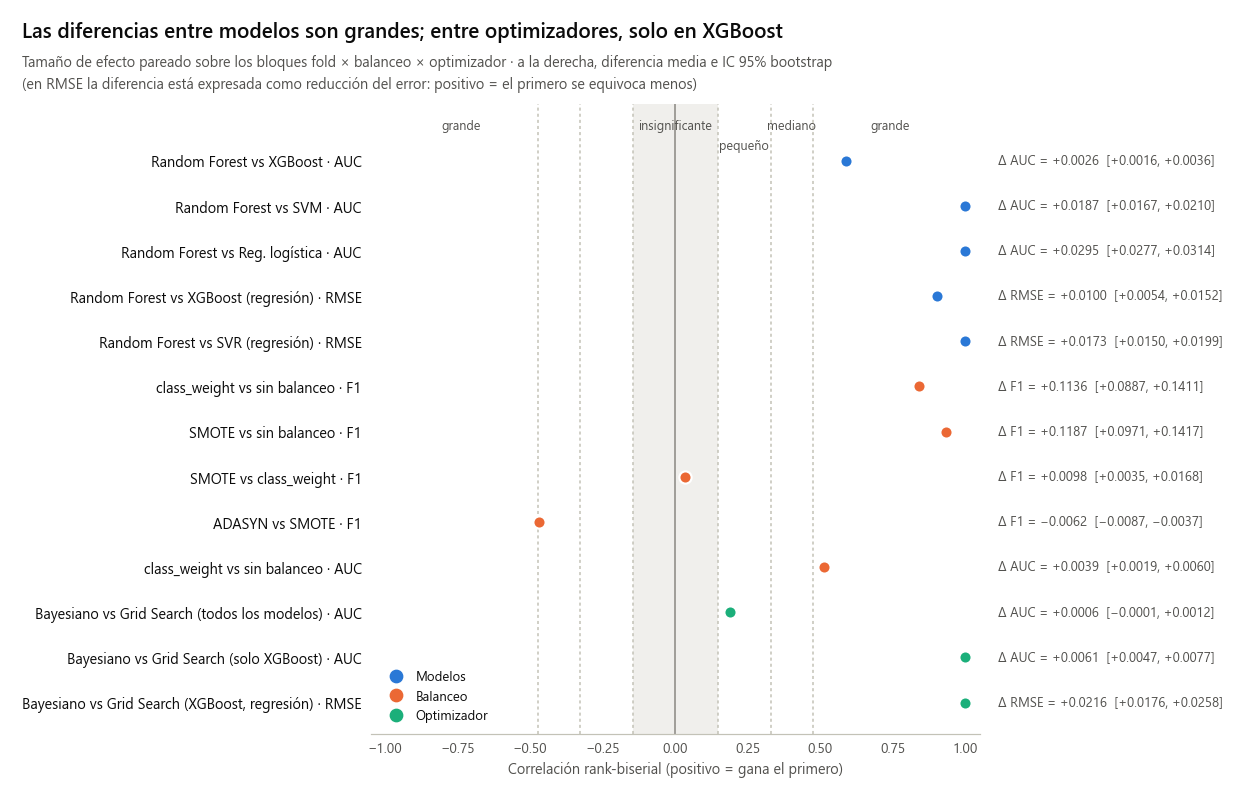

In [11]:
COLOR_FAMILIA = {"Modelos": AZUL, "Balanceo": NARANJA, "Optimizador": AQUA}
fig, ax = plt.subplots(figsize=(11, 6.2), layout="constrained")
n = len(tabla19)
y = np.arange(n)[::-1]
ax.axvspan(-0.147, 0.147, color=GRIS_NEUTRO, lw=0, zorder=0)
for limite in [0.147, 0.33, 0.474]:
    for signo_limite in (-1, 1):
        ax.axvline(signo_limite * limite, color=EJE, lw=1, ls=(0, (2, 2)), zorder=1)
for x, altura, texto in [(0, 0.15, "insignificante"), (0.2385, -0.3, "pequeño"), (0.402, 0.15, "mediano"),
                         (0.74, 0.15, "grande"), (-0.74, 0.15, "grande")]:
    ax.text(x, n - 0.45 + altura, texto, ha="center", fontsize=8.3, color=TINTA_2)
ax.axvline(0, color=TINTA_3, lw=1)
for yi, fila in zip(y, tabla19.itertuples()):
    color = COLOR_FAMILIA[fila.familia]
    ax.plot(fila.rank_biserial, yi, "o", ms=8, color=color, mec=FONDO, mew=1.4, zorder=3)
    signo = "+" if fila.diferencia >= 0 else "−"
    unidad = {"AUC": "AUC", "F1": "F1", "RMSE": "RMSE"}[fila.metrica]
    ax.text(1.03, yi, f"Δ {unidad} = {signo}{abs(fila.diferencia):.4f}  [{fila.ic_inf:+.4f}, {fila.ic_sup:+.4f}]".replace("-", "−"),
            transform=ax.get_yaxis_transform(), va="center", fontsize=8.6, color=TINTA_2)
ax.set_yticks(y, labels=[f"{f.comparacion} · {f.metrica}" for f in tabla19.itertuples()])
ax.tick_params(axis="y", labelcolor=TINTA)
ax.set(xlim=(-1.05, 1.05), ylim=(-0.7, n + 0.25), xlabel="Correlación rank-biserial (positivo = gana el primero)")
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=8, color=c, label=f) for f, c in COLOR_FAMILIA.items()],
          loc="lower left", fontsize=8.6)
encabezado(fig, "Las diferencias entre modelos son grandes; entre optimizadores, solo en XGBoost",
           "Tamaño de efecto pareado sobre los bloques fold × balanceo × optimizador · a la derecha, diferencia media e IC 95% bootstrap\n"
           "(en RMSE la diferencia está expresada como reducción del error: positivo = el primero se equivoca menos)")
guardar(fig, "fig21_tamanos_de_efecto")
plt.show()

> **Resultado:** el tamaño de efecto permite separar lo **consistente** de lo **grande**. Random Forest le gana a SVM y a la regresión logística en el 100% de los pares, por 0.019 y 0.030 de AUC (d_z de 1.9 y 3.4): diferencias grandes en los dos sentidos. Frente a XGBoost también gana en la mayoría de los pares (74%, r = 0.59), pero por solo 0.0026 de AUC: una ventaja consistente y prácticamente irrelevante, coherente con que Nemenyi, DeLong y Diebold–Mariano no la declaren significativa. En regresión la ventaja de Random Forest sobre XGBoost (0.010 de RMSE, 90% de los pares) y sobre SVR (0.017, 100%) es más clara.
>
> En balanceo, pasar de no balancear a `class_weight` o SMOTE sube el F1 en ≈ 0.11–0.12 con efecto grande (r = 0.84 y 0.93), mientras que SMOTE frente a `class_weight` es insignificante (r = 0.03, p = 0.74): son intercambiables, igual que en el diagrama de diferencia crítica, y ADASYN queda levemente por debajo de SMOTE en el promedio de modelos (−0.006 de F1, efecto mediano). `class_weight` también sube el AUC en 0.004 con un r de 0.51: otra vez, consistente pero pequeño en términos absolutos. En optimizadores, Bayesiano frente a Grid Search tiene un efecto pequeño en el conjunto de modelos (+0.0006 de AUC, r = 0.19, p Holm = 0.19), pero en XGBoost gana en el 100% de los pares (+0.006 de AUC en clasificación y −0.022 de RMSE en regresión, d_z de 1.8 y 4.0). La conclusión del notebook de resultados se sostiene con números: **el optimizador solo importa en XGBoost**.

## 5. Intervalos de confianza bootstrap de las configuraciones finales

Para reportar la incertidumbre de las métricas finales se remuestrean los 5,320 vinos 2,000 veces (en clasificación, estratificado por clase para mantener el 19% de vinos buenos) y se toma el percentil 2.5–97.5. Se incluyen las dos configuraciones recomendadas y, en clasificación, la alternativa calibrada (Random Forest con `class_weight`).

In [12]:
B_BOOT = 2000
recomendada_clf, recomendada_reg = recomendada(resumen_clf, "clasificacion"), recomendada(resumen_reg, "regresion")
alternativa = fila_combo("Random Forest", "class_weight", "Bayesiano")
METRICAS_CLF = {"AUC": roc_auc_score, "PR-AUC": average_precision_score, "Brier": brier_score_loss,
                "F1 (umbral 0.5)": lambda y, s: f1_score(y, s >= 0.5),
                "Recall (umbral 0.5)": lambda y, s: recall_score(y, s >= 0.5),
                "Precisión (umbral 0.5)": lambda y, s: precision_score(y, s >= 0.5),
                "Accuracy (umbral 0.5)": lambda y, s: accuracy_score(y, s >= 0.5)}
METRICAS_REG = {"RMSE": lambda y, p: np.sqrt(np.mean((y - p) ** 2)), "MAE": mean_absolute_error, "R²": r2_score}
filas = []
for nombre_cfg, fila in [("recomendada", recomendada_clf), ("alternativa calibrada", alternativa)]:
    s = serie(oof_clf, fila, "score")
    for metrica, funcion in METRICAS_CLF.items():
        valor, inf, sup = ic_bootstrap(funcion, y_clf, s, B=B_BOOT, semilla=config.RANDOM_STATE, estratificar=True)
        filas.append({"tarea": "clasificacion", "configuracion": etiqueta_combo(fila["modelo"], fila["balanceo"],
                      fila["optimizador"], "clasificacion") + f" ({nombre_cfg})", "metrica": metrica,
                      "valor": valor, "ic95_inf": inf, "ic95_sup": sup})
p = serie(oof_reg, recomendada_reg, "pred")
for metrica, funcion in METRICAS_REG.items():
    valor, inf, sup = ic_bootstrap(funcion, y_reg, p, B=B_BOOT, semilla=config.RANDOM_STATE)
    filas.append({"tarea": "regresion", "configuracion": etiqueta_combo(recomendada_reg["modelo"], "no_aplica",
                  recomendada_reg["optimizador"], "regresion") + " (recomendada)", "metrica": metrica,
                  "valor": valor, "ic95_inf": inf, "ic95_sup": sup})
tabla20 = pd.DataFrame(filas)
tabla20["ancho_ic"] = tabla20["ic95_sup"] - tabla20["ic95_inf"]
guardar_tabla(tabla20.round(5), "tabla20_ic_bootstrap_configuraciones_finales")
display(tabla20.round(3))

,tarea,configuracion,metrica,valor,ic95_inf,ic95_sup,ancho_ic
0,clasificacion,Random Forest · ADASYN · Random Search (recomendada),AUC,0.855,0.843,0.866,0.024
1,clasificacion,Random Forest · ADASYN · Random Search (recomendada),PR-AUC,0.567,0.539,0.598,0.058
2,clasificacion,Random Forest · ADASYN · Random Search (recomendada),Brier,0.129,0.125,0.134,0.009
3,clasificacion,Random Forest · ADASYN · Random Search (recomendada),F1 (umbral 0.5),0.575,0.554,0.595,0.041
4,clasificacion,Random Forest · ADASYN · Random Search (recomendada),Recall (umbral 0.5),0.671,0.642,0.702,0.059
5,clasificacion,Random Forest · ADASYN · Random Search (recomendada),Precisión (umbral 0.5),0.503,0.483,0.523,0.041
6,clasificacion,Random Forest · ADASYN · Random Search (recomendada),Accuracy (umbral 0.5),0.812,0.801,0.822,0.020
7,clasificacion,Random Forest · class_weight · Bayesiano (alternativa calibrada),AUC,0.859,0.848,0.871,0.023
8,clasificacion,Random Forest · class_weight · Bayesiano (alternativa calibrada),PR-AUC,0.586,0.557,0.616,0.059
9,clasificacion,Random Forest · class_weight · Bayesiano (alternativa calibrada),Brier,0.109,0.106,0.113,0.007


> **Resultado:** la configuración recomendada de clasificación tiene AUC 0.855 (IC 95% ≈ 0.84–0.87) y F1 0.575 (≈ 0.55–0.60); la alternativa con `class_weight` discrimina igual o mejor (AUC 0.859) y tiene mejor Brier (0.109 frente a 0.129, con intervalos que no se solapan), pero con el umbral de 0.5 su F1 es 0.48, porque detecta pocos vinos buenos: necesita el umbral ≈ 0.3 que se eligió en la evaluación detallada. En regresión, Random Forest con Grid Search tiene RMSE 0.679 (≈ 0.66–0.70) y R² 0.40 (≈ 0.39–0.42). Los intervalos son angostos (± 0.01 a 0.03 según la métrica) porque se apoyan en 5,320 predicciones; son coherentes con la variación entre folds que muestran las tablas del notebook de resultados.

## 6. Conclusiones de las pruebas estadísticas

1. **El modelo es la decisión con más efecto** (W de Kendall 0.94 en clasificación y 0.92 en regresión). Random Forest y XGBoost no se distinguen con ninguna prueba (Nemenyi, DeLong p Holm = 0.14, Diebold–Mariano p Holm = 0.15); Random Forest supera con significancia a todos los demás.
2. **Significativo no es lo mismo que importante.** Friedman detecta diferencias entre optimizadores en clasificación (p = 0.037), pero con W = 0.02; Random Forest le gana a XGBoost en el 74% de los pares, pero por 0.0026 de AUC. Los tamaños de efecto y las diferencias en unidades de la métrica evitan sobreinterpretar decimales.
3. **El balanceo no cambia la discriminación** (DeLong: solo `class_weight` en Random Forest, +0.0045 de AUC) **pero sí la detección**: +0.11 a +0.12 de F1 con efecto grande. SMOTE y `class_weight` son equivalentes (r = 0.03).
4. **El optimizador solo importa en XGBoost**, donde Bayesiano gana en el 100% de los pares (d_z de 1.8 en AUC y 4.0 en RMSE).
5. **El MCS** deja en el grupo de las mejores solo configuraciones de Random Forest (más una de XGBoost en clasificación) y **ninguna con SMOTE o ADASYN** cuando se evalúan las probabilidades; en regresión el conjunto es únicamente Random Forest con Grid Search, que coincide con la configuración recomendada.